In [2]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import BoundaryNorm
import seaborn as sns
import cartopy.crs as ccrs
from pathlib import Path

In [50]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

In [ ]:
country_raster_1km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-1km.tif')
global_building_minerals = rio.open(RESULTS / 'features' / 'building-mineral-stock-1km.tif').read(1)
world_map_ = gpd.read_file(DATA / 'simplified-world-map' / 'world-map.shp')
world_map = world_map_.drop([31])
world_map = world_map.to_crs('ESRI:54012')

In [12]:
def plot_box_by_density_and_gdp(
    ax,
    summary,
    den_labels,
    gdp_labels,
    colors,
    ylabel,
):
    """
    Generic plotting function for both per-capita and per-area stock
    """

    nbins = len(den_labels)
    xpos_all = np.arange(1, nbins + 1)

    # offsets = np.linspace(-0.35, 0.35, len(gdp_labels))
    offsets = np.linspace(-0.40, 0.40, len(gdp_labels))
    width = 0.06

    for k, (gdp, off) in enumerate(zip(gdp_labels, offsets)):
        sub = summary[summary["gdp_bin"] == gdp]
        stats, xpos = [], []

        for i, den in enumerate(den_labels):
            row = sub[sub["den_bin"] == den]

            if row.empty or row["count"].values[0] < 5:
                continue

            r = row.iloc[0]

            stats.append({
                "med": r["median"],
                "q1": r["p25"],
                "q3": r["p75"],
                "whislo": r["p5"],
                "whishi": r["p95"]
            })

            xpos.append(i + 1)

        if not stats:
            continue

        ax.bxp(
            stats,
            positions=np.array(xpos) + off,
            widths=width,
            showfliers=False,
            patch_artist=True,
            boxprops=dict(facecolor=colors[k], alpha=0.75, edgecolor="black"),
            medianprops=dict(color="black", lw=1.3),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black"),
        )

    ax.set_ylim(1e-3, 1e7)
    ax.set_xticks(xpos_all)
    ax.set_xticklabels(den_labels, rotation=35, ha="right")
    ax.set_xlabel("population density (cap km$^{-2}$)")
    ax.set_ylabel(ylabel)
    ax.set_yscale("log")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

In [7]:
density_bins = [1, 10, 50, 100, 500, 1000, 5000, 10000, np.inf]
density_labels = [
    "1-10", "10-50", "50-100", "100-500",
    "500-1000", "1000-5000", "5000-10000", "≥10000"
]

In [8]:
gdp_bins = [0, 1000, 2000, 3000, 5000, 8000, 12000, 20000, 30000, 45000, 60000, 90000, np.inf]
gdp_labels = [
    "<1000",
    "1k-2k",
    "2k-3k",
    "3k-5k",
    "5k-8k",
    "8k-12k",
    "12k-20k",
    "20k-30k",
    "30k-45k",
    "45k-60k",
    "60k-90k",
    "≥90k"
]

In [4]:
summary_1 = pd.read_csv(RESULTS / 'bins-summary-1.csv')
summary_2 = pd.read_csv(RESULTS / 'bins-summary-2.csv')

In [47]:
display_extent_1km = [country_raster_1km_.bounds.left, country_raster_1km_.bounds.right, country_raster_1km_.bounds.bottom, country_raster_1km_.bounds.top]
cmap = plt.get_cmap("YlOrRd", 5)  
bounds = np.array([1, 2, 3, 4, 5, 6])
norm = BoundaryNorm(bounds, cmap.N)

In [43]:
classified = np.zeros(global_building_minerals.shape, dtype=np.uint8)
bins = np.array([0, 1e3, 1e4, 1e5, 1e6, np.inf])
classified[global_building_minerals > 0] = np.digitize(global_building_minerals[global_building_minerals > 0], bins, right=False)
classified_plot = np.ma.masked_where(classified == 0, classified)

In [52]:
np.unique(classified, return_counts=True)

(array([0, 1, 2, 3, 4, 5], dtype=uint8),
 array([529334685,  29008620,   9677421,   3851724,    810118,     25600]))

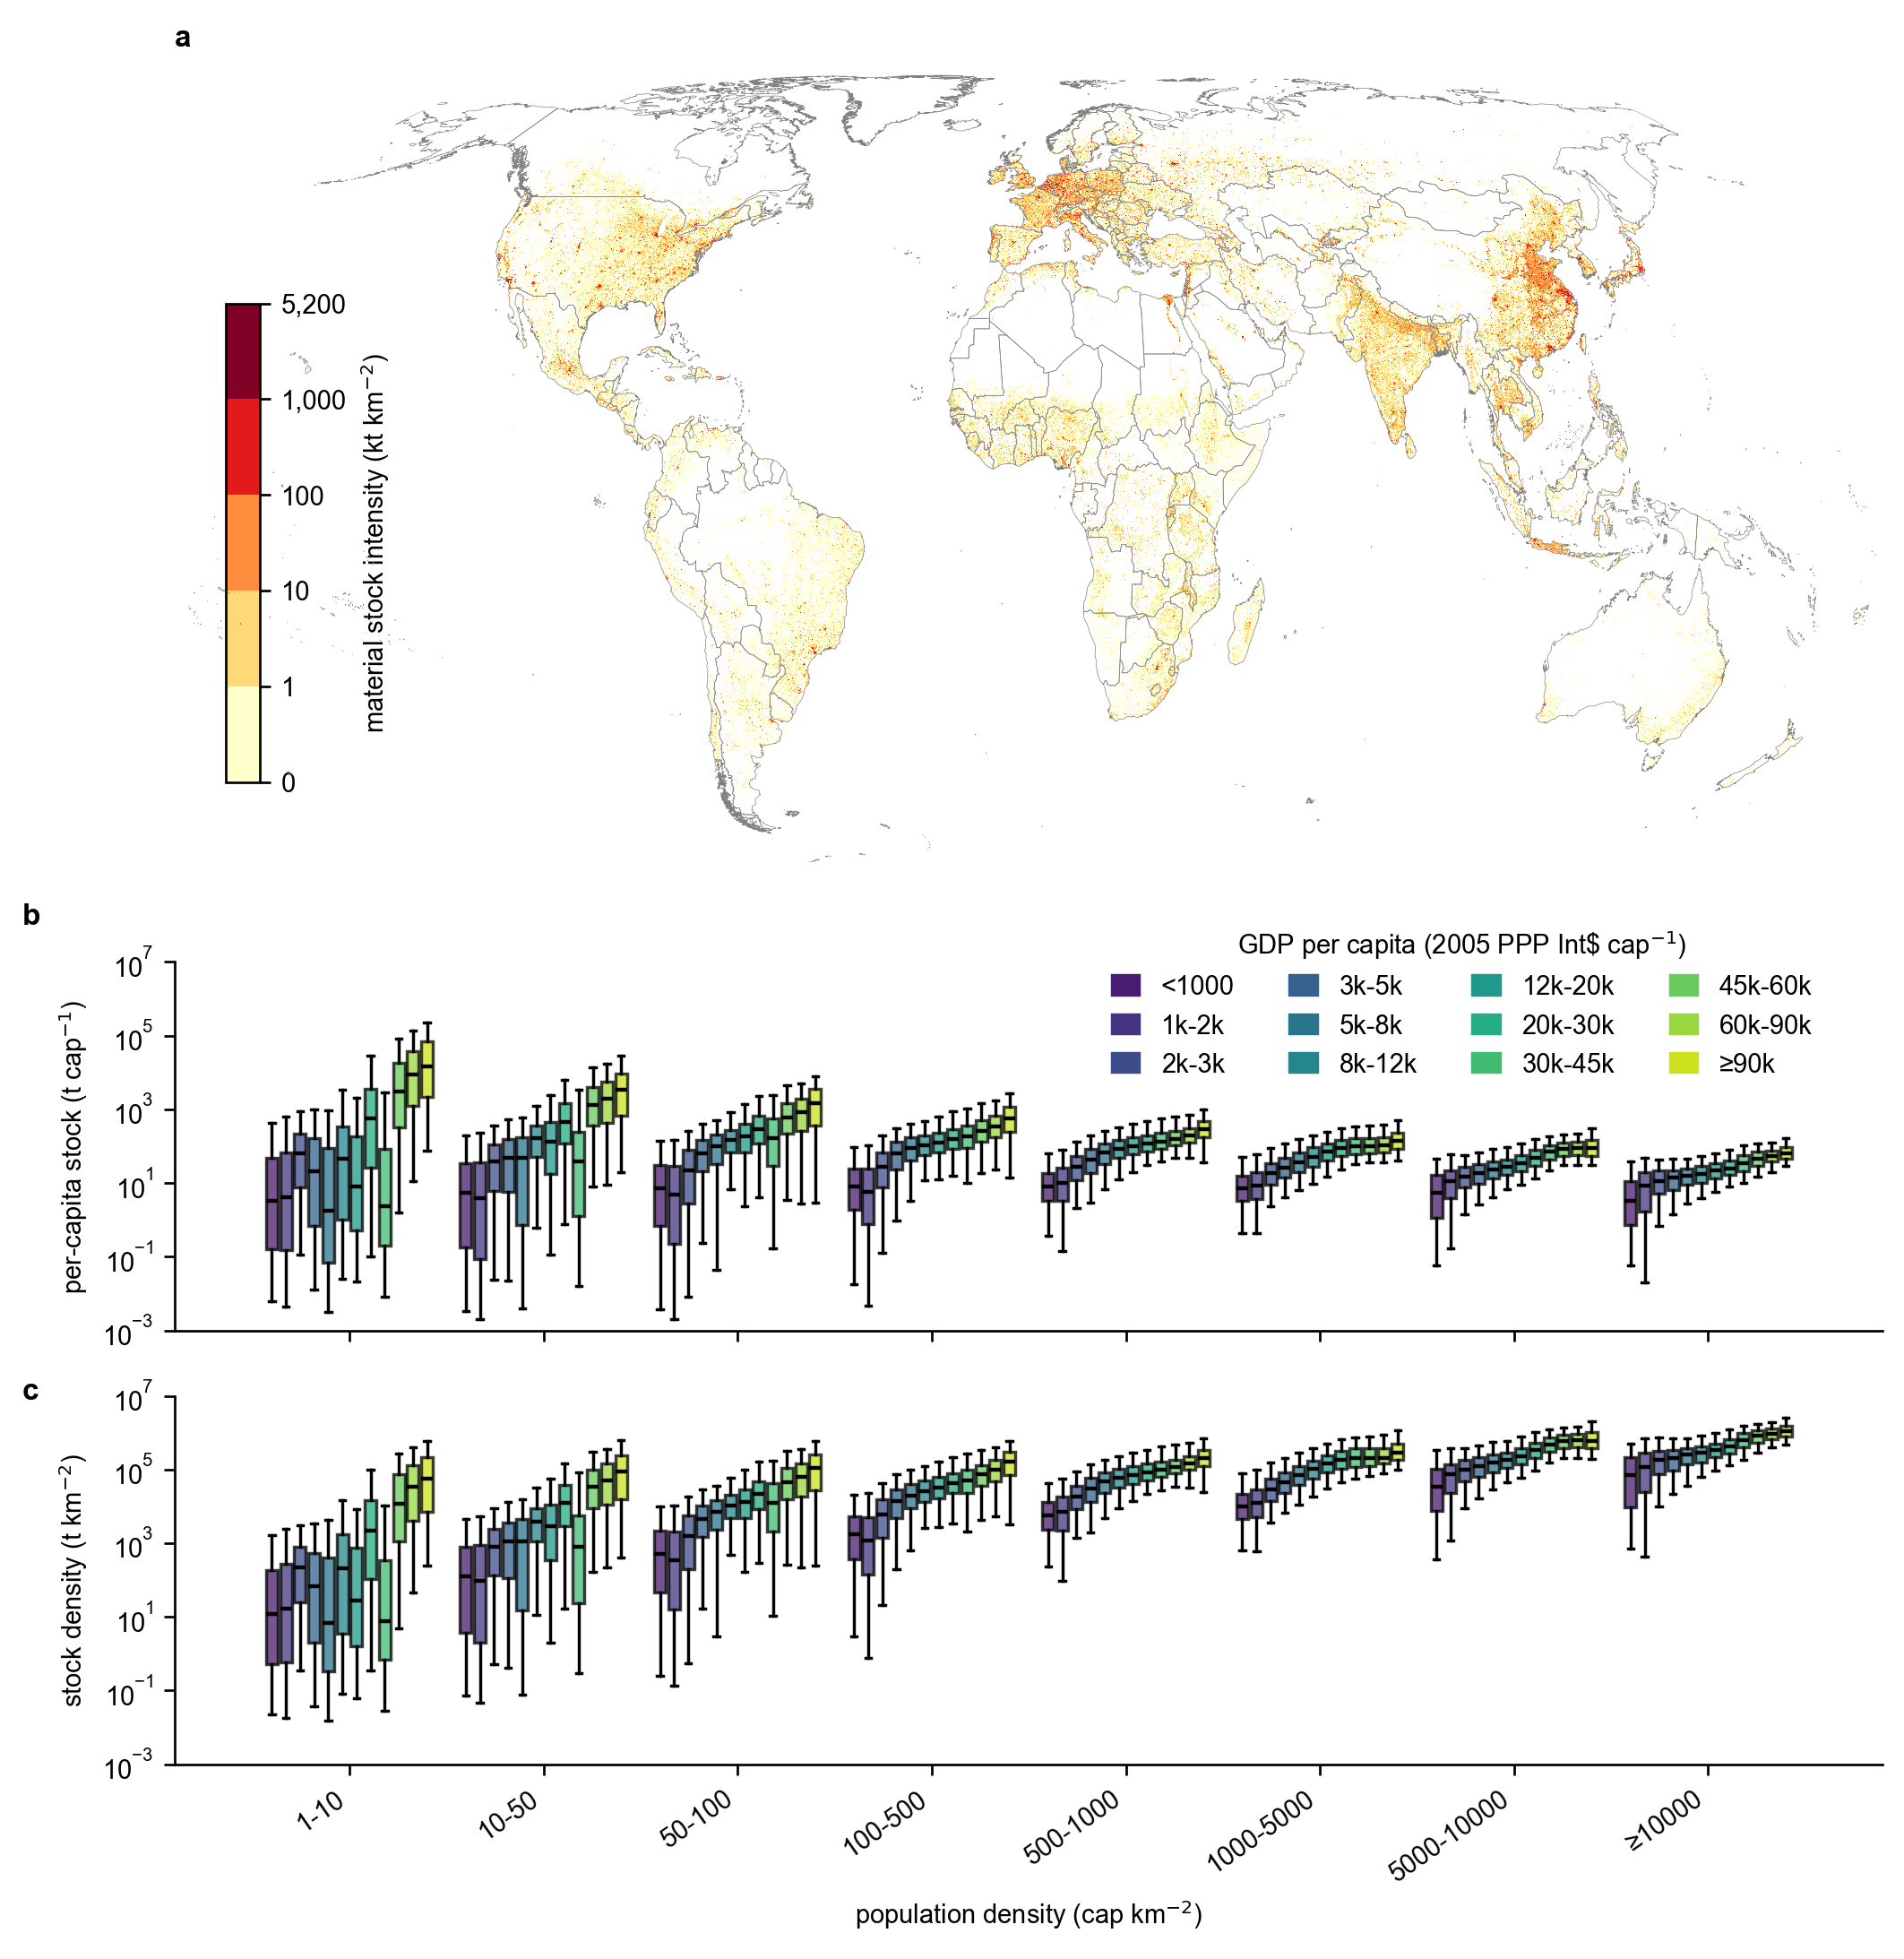

In [ ]:
fig = plt.figure(figsize=(8.5, 9), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'
colors = sns.color_palette("viridis", len(gdp_labels))

gs = fig.add_gridspec(3, 4, height_ratios=[2.5, 1, 1])
ax1 = fig.add_subplot(gs[0, :], projection=ccrs.EckertIV())

world_map.plot(color='none', edgecolor='grey', lw=0.2, ax=ax1, zorder=10)
im1 = ax1.imshow(classified_plot, cmap=cmap, norm=norm, interpolation="nearest", extent=display_extent_1km, zorder=5)
ax1.set_facecolor("white")
ax1.axis('off')
ax1.set_ylim(-7.2e6, 8.6e6)
ax1.set_title('a', loc='left', fontdict={'size':15, 'weight': 'semibold'})


cax1 = ax1.inset_axes([0.03, 0.10, 0.02, 0.60])
cbar1 = fig.colorbar(im1, cax=cax1, orientation='vertical', label=r'material stock intensity (kt km$^{-2}$)')
cbar1.set_ticks(np.arange(1, 7))  # 1,2,3,4,5,6
cbar1.set_ticklabels([
    "0",
    "1",
    "10",
    "100",
    "1,000",
    '5,200'
])


ax2 = fig.add_subplot(gs[1, :])
ax3 = fig.add_subplot(gs[2, :])

plot_box_by_density_and_gdp(
    ax2,
    summary_1,
    density_labels,
    gdp_labels,
    colors,
    ylabel="per-capita stock (t cap$^{-1}$)",
)
ax2.set_xticklabels([])
ax2.set_xlabel('')

plot_box_by_density_and_gdp(
    ax3,
    summary_2,
    density_labels,
    gdp_labels,
    colors,
    ylabel="stock density (t km$^{-2}$)",
)

handles = [
    plt.Rectangle((0,0), 1, 1, color=colors[k], label=gdp)
    for k, gdp in enumerate(gdp_labels)
]
fig.legend(
    handles=handles,
    title=r"GDP per capita (2005 PPP Int\$ cap$^{-1}$)",
    loc="upper center",
    ncol=4,   # 控制每行几个
    fontsize=9,
    bbox_to_anchor=(0.77, 0.54),
    handlelength=1.0,
    frameon=False
)

fig.text(0.00, 0.53, 'b', fontdict={'size':15, 'weight': 'semibold'})
fig.text(0.00, 0.29, 'c', fontdict={'size':15, 'weight': 'semibold'})

plt.show()

In [ ]:
# Keep the final width within 180 mm without distorting panel proportions.
# Embedded TrueType text; matching 300-dpi raster copies for Extended Data.
from final_figure_export import export_final_figure
export_report = export_final_figure(fig, FIGURES / 'Extended-Data-Figure-2', jpg_dpi=300)


In [ ]:
# PDF, PNG and JPG are exported together in the preceding cell.
